# Road Damage Object Detection — YOLO Model Comparison

Road damage detection with the latest YOLO versions: **YOLO26n**, **YOLO12n** and **YOLO11n**.

**Project steps**
1. Install and import the libraries.
2. Download the Road Damage dataset from Roboflow (our own forked version).
3. Check the classes, the number of images and `data.yaml`.
4. Train three different YOLO versions with the same settings.
5. Compare mAP, Precision, Recall, IoU, FPS and model size.
6. Hyperparameter tuning on the best model.
7. Final evaluation on the test set, per-class results and confusion matrix.
8. Save the best model (`best.pt`) for the Gradio app (`app.py`).

> Model selection is done on the **validation** set. The **test** set is used only for the final report.

## 1. Install Libraries

In [1]:
!pip install -q -U ultralytics roboflow

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


## 2. Import Libraries

In [2]:
import os
os.environ["WANDB_MODE"] = "disabled"   

import json
import time
import glob
import yaml
import random
import shutil
from getpass import getpass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

import torch
from roboflow import Roboflow
from kaggle_secrets import UserSecretsClient
from ultralytics import YOLO

print("GPU available:", torch.cuda.is_available())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU available: True


## 3. Download Dataset from Roboflow

The dataset was **forked** to our account and we created **Version 1** (resize to 640×640, no augmentation).
- Workspace: `abdelaziz-vibr3`
- Project: `road-damage-l1ju7-njbww`

The Roboflow API key is read from **Kaggle Secrets** (name: `ROBOFLOW_API_KEY`). If it is not found, the notebook asks for it with a hidden input. **Never upload the key to GitHub.**

In [3]:
API_KEY = UserSecretsClient().get_secret("ROBOFLOW_API_KEY") 

rf = Roboflow(api_key=API_KEY)
project = rf.workspace("abdelaziz-vibr3").project("road-damage-l1ju7-njbww")
version = project.version(1)
dataset = version.download("yolov8")

DATASET_DIR = os.path.abspath(dataset.location)
print("Dataset folder:", DATASET_DIR)

loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov8 in progress : 95.0%
Version export complete for yolov8 format



Extracting Dataset Version Zip to road-damage-1 in yolov8:: 100%|██████████| 13518/13518 [00:01<00:00, 8664.13it/s] 

Dataset folder: /kaggle/working/road-damage-1


## 4. Configuration and Data Check

In [4]:
OUTPUT_DIR = os.path.abspath("road_damage_outputs")
EXPERIMENTS_DIR = os.path.join(OUTPUT_DIR, "experiments")
PLOTS_DIR = os.path.join(OUTPUT_DIR, "plots")
RESULTS_JSON = os.path.join(OUTPUT_DIR, "results.json")

EPOCHS = 20
BATCH_SIZE = 16
IMAGE_SIZE = 640
LEARNING_RATE = 0.001
SEED = 42
NUM_SPEED_IMAGES = 30

os.makedirs(EXPERIMENTS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

with open(os.path.join(DATASET_DIR, "data.yaml"), "r", encoding="utf-8") as f:
    original_cfg = yaml.safe_load(f)
names = original_cfg["names"]
CLASS_NAMES = list(names.values()) if isinstance(names, dict) else list(names)
print("Classes:", CLASS_NAMES)


HAS_TEST = os.path.isdir(os.path.join(DATASET_DIR, "test", "images"))
for split in ["train", "valid", "test"]:
    print(split, "->", len(glob.glob(os.path.join(DATASET_DIR, split, "images", "*"))), "images")

DATA_YAML = os.path.join(OUTPUT_DIR, "data_fixed.yaml")
with open(DATA_YAML, "w", encoding="utf-8") as f:
    yaml.dump({
        "path": DATASET_DIR,
        "train": "train/images",
        "val": "valid/images",
        "test": "test/images" if HAS_TEST else "valid/images",
        "names": {i: n for i, n in enumerate(CLASS_NAMES)},
    }, f)
print("Data YAML:", DATA_YAML)

Classes: ['alligator', 'block', 'crack', 'edge', 'longitudinal', 'pothole', 'transverse']
train -> 4730 images
valid -> 1351 images
test -> 676 images
Data YAML: /kaggle/working/road_damage_outputs/data_fixed.yaml


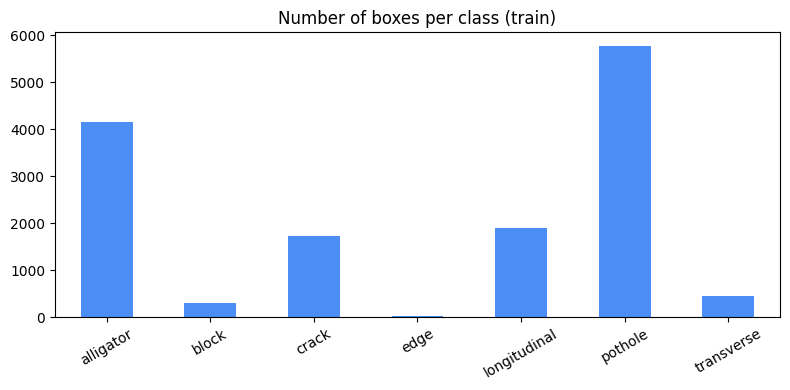

In [5]:
counts = np.zeros(len(CLASS_NAMES), dtype=int)
for label_file in glob.glob(os.path.join(DATASET_DIR, "train", "labels", "*.txt")):
    with open(label_file) as f:
        for line in f:
            if line.strip():
                counts[int(float(line.split()[0]))] += 1

pd.Series(counts, index=CLASS_NAMES).plot(kind="bar", figsize=(8, 4), color="#4C8DF6")
plt.title("Number of boxes per class (train)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 5. Train Three Different YOLO Models

We compare three YOLO versions: **YOLO26n** (the newest), **YOLO12n** and **YOLO11n**. We use the nano size to keep training time reasonable, and all models share the same settings so the comparison is fair.

In [6]:
MODELS = ["yolo26n.pt", "yolo12n.pt", "yolo11n.pt"]

def get_images(folder_name):
    folder = os.path.join(DATASET_DIR, folder_name, "images")
    return sorted(
        os.path.join(folder, name) for name in os.listdir(folder)
        if name.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    )

VAL_IMAGES = get_images("valid")
TEST_IMAGES = get_images("test") if HAS_TEST else VAL_IMAGES
TEST_SPLIT = "test"
print("Validation images:", len(VAL_IMAGES), "| Test images:", len(TEST_IMAGES))

Validation images: 1351 | Test images: 676


In [7]:
def measure_speed(model, image_paths, device=None, max_images=NUM_SPEED_IMAGES):
    image_paths = image_paths[:max_images]
    for image_path in image_paths[:2]:   
        model.predict(image_path, imgsz=IMAGE_SIZE, device=device, verbose=False)

    start = time.time()
    for image_path in image_paths:
        model.predict(image_path, imgsz=IMAGE_SIZE, device=device, verbose=False)
    elapsed = time.time() - start

    return round(elapsed / len(image_paths) * 1000, 2), round(len(image_paths) / elapsed, 2)


def evaluate(weights_path, split):
   
    m = YOLO(weights_path).val(data=DATA_YAML, split=split, imgsz=IMAGE_SIZE, plots=False, verbose=False)
    return {"mAP50": round(float(m.box.map50), 4), "mAP50-95": round(float(m.box.map), 4),
            "precision": round(float(m.box.mp), 4), "recall": round(float(m.box.mr), 4)}


def train_one_model(weights_name):
    model_name = weights_name.replace(".pt", "")

    print(f"\nTraining {model_name} ...")
    model = YOLO(weights_name)
    model.train(
        data=DATA_YAML,
        epochs=EPOCHS,
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        optimizer="Adam",
        lr0=LEARNING_RATE,
        seed=SEED,
        patience=10,
        project=EXPERIMENTS_DIR,
        name=model_name,
        exist_ok=True,
        workers=2,
        plots=False,
    )

    best_weights = str(model.trainer.best)
    best_model = YOLO(best_weights)
    avg_ms, fps = measure_speed(best_model, TEST_IMAGES, device=0)
    _, cpu_fps = measure_speed(best_model, TEST_IMAGES, device="cpu", max_images=10)

    return {
        "model_name": model_name,
        "best_weights_path": best_weights,
        "val_mAP50-95": evaluate(best_weights, "val")["mAP50-95"],   
        **{f"test_{k}": v for k, v in evaluate(best_weights, TEST_SPLIT).items()},  
        "model_size_mb": round(os.path.getsize(best_weights) / (1024 * 1024), 2),
        "inference_ms": avg_ms,
        "fps": fps,
        "cpu_fps": cpu_fps,
    }

In [8]:
all_results = []

for weights in MODELS:
    all_results.append(train_one_model(weights))

    
    with open(RESULTS_JSON, "w", encoding="utf-8") as f:
        json.dump(all_results, f, indent=2, ensure_ascii=False)

print("Training finished. Results saved to:", RESULTS_JSON)


Training yolo26n ...
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/road_damage_outputs/data_fixed.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n, nbs=64,

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


       2/20      3.02G      1.908       3.11     0.0216         26        640: 100% ━━━━━━━━━━━━ 296/296 6.8it/s 43.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 43/43 5.4it/s 8.0s
                   all       1346       4265      0.361      0.229      0.177      0.083

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/20      3.02G      1.865      2.929    0.02106         24        640: 100% ━━━━━━━━━━━━ 296/296 6.7it/s 44.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 43/43 5.5it/s 7.9s
                   all       1346       4265      0.384      0.212      0.168     0.0692

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/20      3.02G      1.838       2.81    0.02079         27        640: 100% ━━━━━━━━━━━━ 296/296 6.7it/s 44.4s
                 Class     Images  Instances      Box

## 6. Compare Models

In [9]:
def box_iou(box_a, box_b):
    x1 = max(float(box_a[0]), float(box_b[0]))
    y1 = max(float(box_a[1]), float(box_b[1]))
    x2 = min(float(box_a[2]), float(box_b[2]))
    y2 = min(float(box_a[3]), float(box_b[3]))
    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area_a = max(0, float(box_a[2]) - float(box_a[0])) * max(0, float(box_a[3]) - float(box_a[1]))
    area_b = max(0, float(box_b[2]) - float(box_b[0])) * max(0, float(box_b[3]) - float(box_b[1]))
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0


def calculate_mean_iou(model_path, image_paths, limit=100):
    
    model = YOLO(model_path)
    iou_values = []

    for image_path in image_paths[:limit]:
        label_path = os.path.join(os.path.dirname(os.path.dirname(image_path)), "labels",
                                  os.path.splitext(os.path.basename(image_path))[0] + ".txt")
        if not os.path.exists(label_path):
            continue
        width, height = Image.open(image_path).size

        ground_truth = []
        for line in open(label_path):
            parts = line.split()
            if len(parts) == 5:
                c, xc, yc, w, h = map(float, parts)
                ground_truth.append([int(c), (xc - w / 2) * width, (yc - h / 2) * height,
                                     (xc + w / 2) * width, (yc + h / 2) * height])

        result = model.predict(image_path, imgsz=IMAGE_SIZE, verbose=False)[0]
        preds = [[int(b.cls.item()), *b.xyxy[0].cpu().numpy().tolist(), float(b.conf.item())] for b in result.boxes]

        used = set()
        for pred in sorted(preds, key=lambda p: p[5], reverse=True):
            best_iou, best_index = 0.0, -1
            for i, gt in enumerate(ground_truth):
                if i in used or gt[0] != pred[0]:
                    continue
                current = box_iou(pred[1:5], gt[1:5])
                if current > best_iou:
                    best_iou, best_index = current, i
            if best_index >= 0:
                used.add(best_index)
                iou_values.append(best_iou)

    return round(float(np.mean(iou_values)), 4) if iou_values else None


for row in all_results:
    row["mean_IoU"] = calculate_mean_iou(row["best_weights_path"], TEST_IMAGES)

with open(RESULTS_JSON, "w", encoding="utf-8") as f:
    json.dump(all_results, f, indent=2, ensure_ascii=False)

results_df = pd.DataFrame(all_results)
display(results_df[["model_name", "val_mAP50-95", "test_mAP50", "test_mAP50-95", "test_precision",
                    "test_recall", "mean_IoU", "fps", "cpu_fps", "model_size_mb"]])

,model_name,val_mAP50-95,test_mAP50,test_mAP50-95,test_precision,test_recall,mean_IoU,fps,cpu_fps,model_size_mb
0,yolo26n,0.2231,0.5902,0.3570,0.6298,0.5605,0.7583,79.54,13.09,5.20
1,yolo12n,0.2223,0.5818,0.3362,0.5999,0.5400,0.7312,61.24,10.40,5.30
2,yolo11n,0.2135,0.5549,0.3317,0.6185,0.5112,0.7797,86.29,13.26,5.25


### What is IoU?

**IoU** (Intersection over Union) measures the overlap between a predicted box and the ground-truth box. mAP is built on top of it. Here we also report the **mean IoU** directly on the test images.

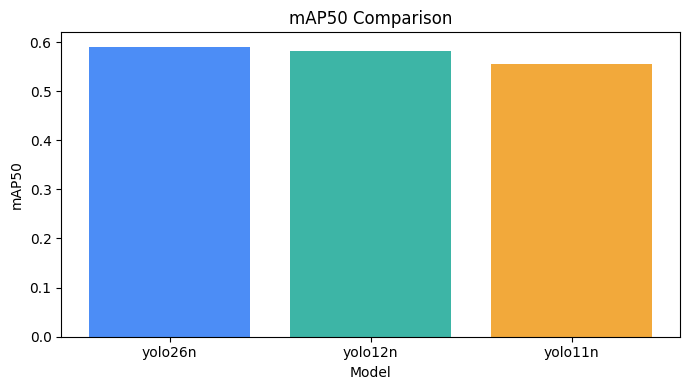

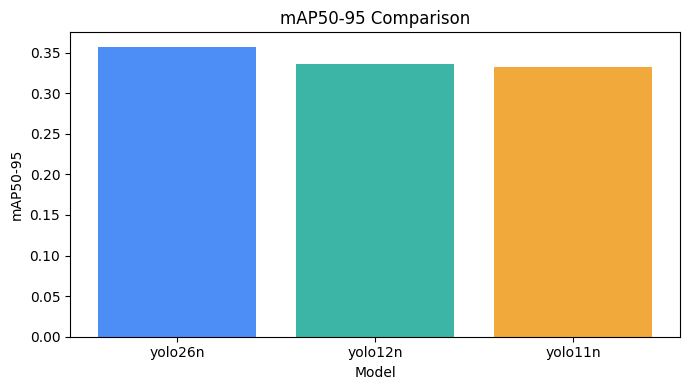

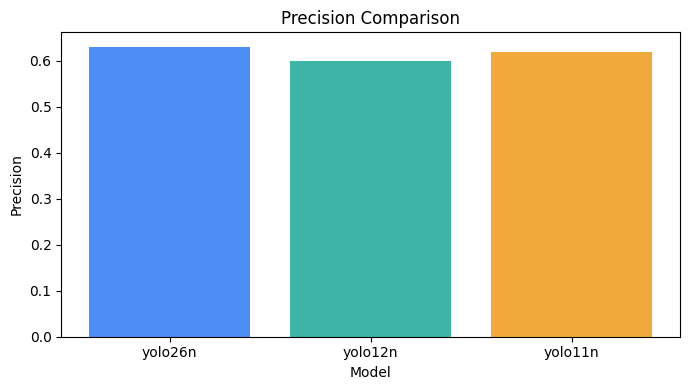

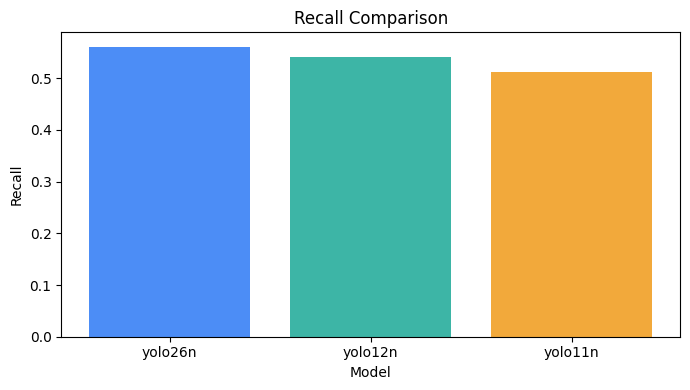

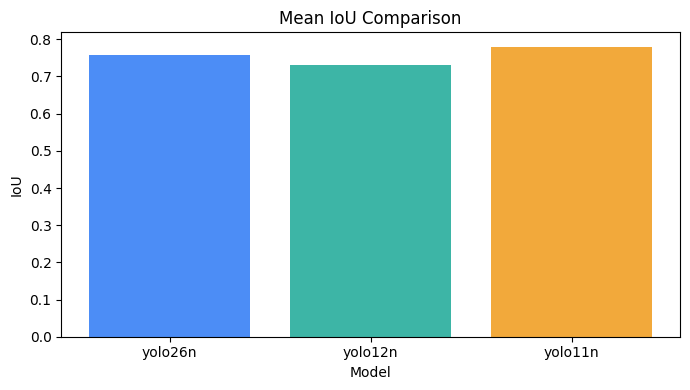

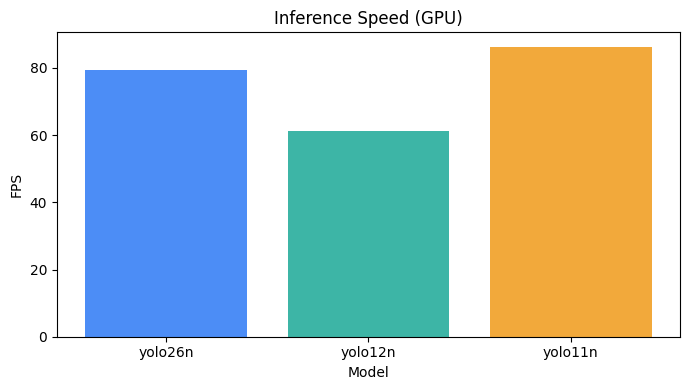

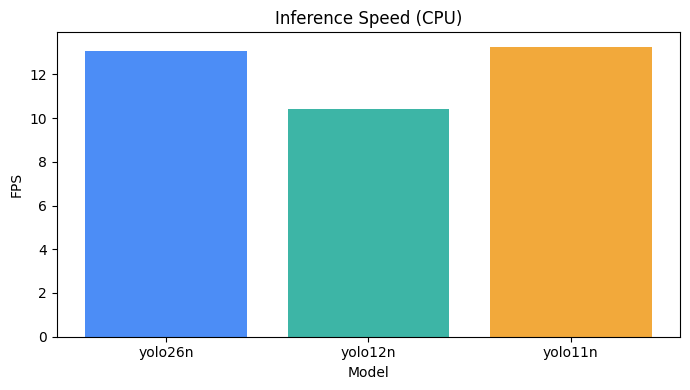

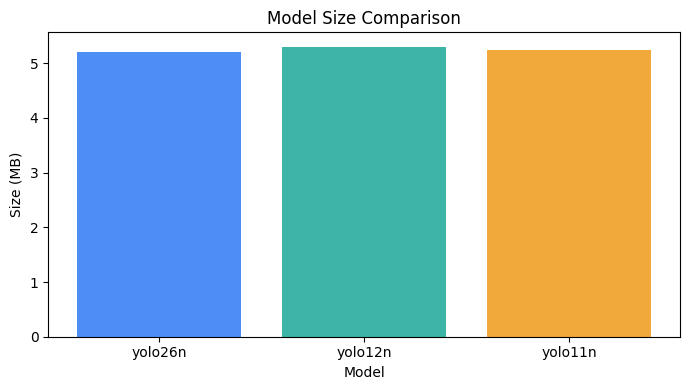

In [10]:
def plot_metric(metric, title, ylabel):
    plt.figure(figsize=(7, 4))
    plt.bar(results_df["model_name"], results_df[metric], color=["#4C8DF6", "#3DB5A6", "#F2A93B"])
    plt.title(title)
    plt.xlabel("Model")
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, metric + ".png"), dpi=150)
    plt.show()

plot_metric("test_mAP50", "mAP50 Comparison", "mAP50")
plot_metric("test_mAP50-95", "mAP50-95 Comparison", "mAP50-95")
plot_metric("test_precision", "Precision Comparison", "Precision")
plot_metric("test_recall", "Recall Comparison", "Recall")
plot_metric("mean_IoU", "Mean IoU Comparison", "IoU")
plot_metric("fps", "Inference Speed (GPU)", "FPS")
plot_metric("cpu_fps", "Inference Speed (CPU)", "FPS")
plot_metric("model_size_mb", "Model Size Comparison", "Size (MB)")

## 7. Hyperparameter Tuning for the Best Model

The best model is chosen by **validation mAP50-95**. Then we try 4 different settings (learning rate and batch size). Every run starts from the **original pretrained weights** and uses the same number of epochs, so the comparison is fair.

In [11]:
best_baseline = max(all_results, key=lambda row: row["val_mAP50-95"])
best_weights_name = best_baseline["model_name"] + ".pt"
print("Best baseline model:", best_baseline["model_name"], "| Val mAP50-95:", best_baseline["val_mAP50-95"])

tuning_rows = []
for lr in [0.0005, 0.002]:
    for batch in [8, 16]:
        run_name = f"{best_baseline['model_name']}_lr{lr}_b{batch}"
        print("Tuning:", run_name)
        model = YOLO(best_weights_name)
        model.train(data=DATA_YAML, epochs=EPOCHS, imgsz=IMAGE_SIZE, batch=batch, optimizer="Adam",
                    lr0=lr, seed=SEED, patience=10, project=EXPERIMENTS_DIR, name=run_name,
                    exist_ok=True, workers=2, plots=False)
        weights = str(model.trainer.best)
        val = evaluate(weights, "val")
        tuning_rows.append({"lr": lr, "batch": batch, "weights": weights,
                            "Val mAP50": val["mAP50"], "Val mAP50-95": val["mAP50-95"]})

tuning_df = pd.DataFrame(tuning_rows).sort_values("Val mAP50-95", ascending=False).reset_index(drop=True)
display(tuning_df.drop(columns=["weights"]))

Best baseline model: yolo26n | Val mAP50-95: 0.2231
Tuning: yolo26n_lr0.0005_b8
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/road_damage_outputs/data_fixed.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum

,lr,batch,Val mAP50,Val mAP50-95
0,0.0005,16,0.3984,0.2292
1,0.0020,16,0.3942,0.2264
2,0.0020,8,0.3709,0.2067
3,0.0005,8,0.3599,0.2053


## 8. Select the Best Model

We compare the best baseline model with the best tuned run (on the validation set), then evaluate the winner on the **test** set.

In [12]:
tuned = tuning_df.iloc[0]
if tuned["Val mAP50-95"] > best_baseline["val_mAP50-95"]:
    BEST_MODEL_PATH = tuned["weights"]
    print("Selected tuned model: lr =", tuned["lr"], "| batch =", tuned["batch"])
else:
    BEST_MODEL_PATH = best_baseline["best_weights_path"]
    print("Selected baseline model.")

best_model = YOLO(BEST_MODEL_PATH)
print("Classes:", best_model.names)

before = evaluate(best_baseline["best_weights_path"], TEST_SPLIT)
after = evaluate(BEST_MODEL_PATH, TEST_SPLIT)
display(pd.DataFrame([{"Stage": "Baseline", **before}, {"Stage": "Final (selected)", **after}]))

Selected tuned model: lr = 0.0005 | batch = 16
Classes: {0: 'alligator', 1: 'block', 2: 'crack', 3: 'edge', 4: 'longitudinal', 5: 'pothole', 6: 'transverse'}
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,391,193 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1904.5±466.1 MB/s, size: 79.5 KB)
val: Scanning /kaggle/working/road-damage-1/test/labels.cache... 676 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 676/676 149.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 43/43 8.1it/s 5.3s
                   all        676       1977       0.63       0.56       0.59      0.357
Speed: 0.9ms preprocess, 3.7ms inference, 0.0ms loss, 1.1ms postprocess per image
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,391,193 parameters, 0 gra

,Stage,mAP50,mAP50-95,precision,recall
0,Baseline,0.5902,0.3570,0.6298,0.5605
1,Final (selected),0.5787,0.3602,0.6017,0.5484


## 9. Per-Class Results and Confusion Matrix

Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,391,193 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2048.9±329.2 MB/s, size: 86.5 KB)
val: Scanning /kaggle/working/road-damage-1/test/labels.cache... 676 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 676/676 141.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 43/43 6.3it/s 6.9s
                   all        676       1977      0.602      0.548      0.579       0.36
Speed: 1.3ms preprocess, 3.9ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-13


,Class,Precision,Recall,mAP50,mAP50-95
2,crack,0.645,0.871,0.859,0.660
1,block,0.662,0.830,0.806,0.614
4,pothole,0.671,0.626,0.670,0.366
5,transverse,0.597,0.552,0.570,0.289
0,alligator,0.607,0.162,0.307,0.143
3,longitudinal,0.429,0.250,0.260,0.089


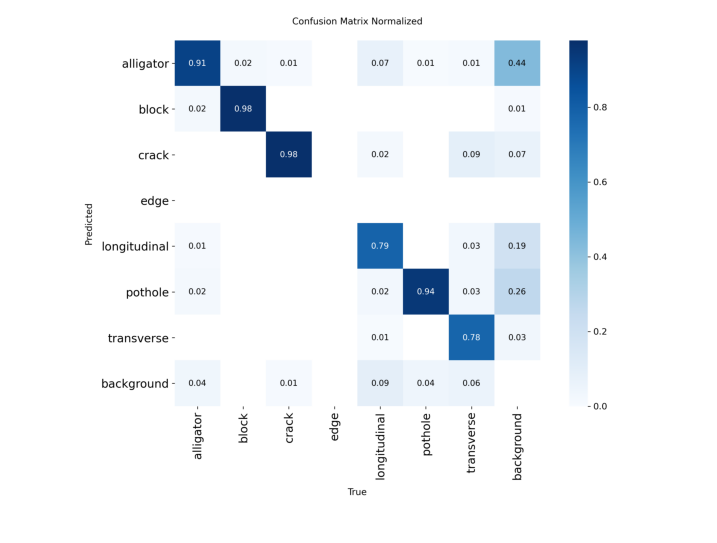

In [13]:
metrics = best_model.val(data=DATA_YAML, split=TEST_SPLIT, imgsz=IMAGE_SIZE, plots=True, verbose=False)

rows = []
for i, c in enumerate(metrics.box.ap_class_index):
    p, r, ap50, ap = metrics.box.class_result(i)
    rows.append({"Class": CLASS_NAMES[c], "Precision": round(p, 3), "Recall": round(r, 3),
                 "mAP50": round(ap50, 3), "mAP50-95": round(ap, 3)})
display(pd.DataFrame(rows).sort_values("mAP50", ascending=False))

plt.figure(figsize=(9, 9))
plt.imshow(Image.open(os.path.join(str(metrics.save_dir), "confusion_matrix_normalized.png")))
plt.axis("off")
plt.show()

## 10. Visualize Predictions

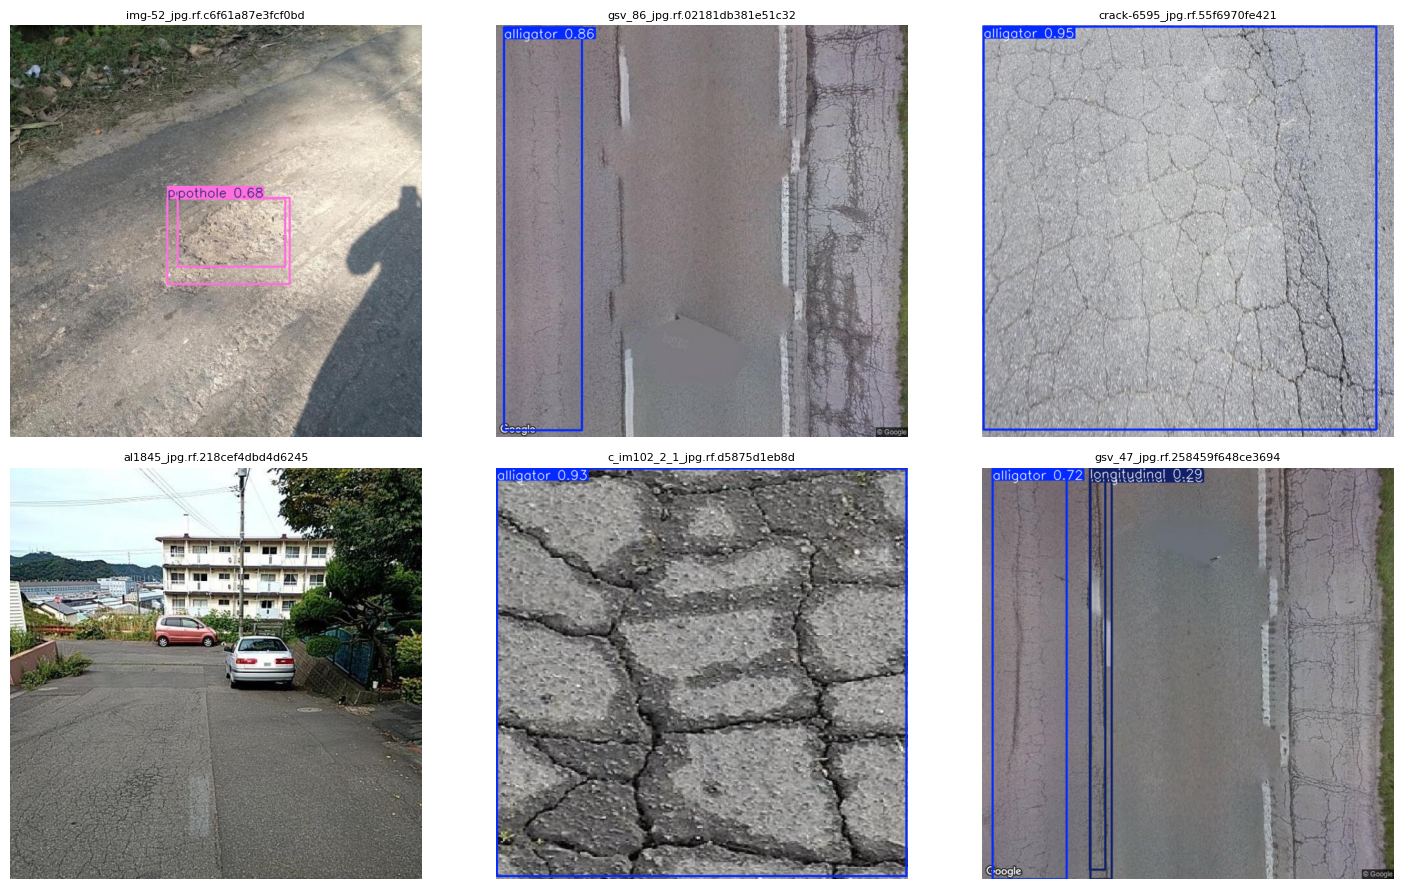

In [14]:
sample_images = random.sample(TEST_IMAGES, min(6, len(TEST_IMAGES)))
predictions = best_model.predict(sample_images, imgsz=IMAGE_SIZE, conf=0.25, verbose=False)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, image_path, result in zip(axes.flatten(), sample_images, predictions):
    ax.imshow(result.plot()[:, :, ::-1])   # BGR to RGB
    ax.set_title(os.path.basename(image_path)[:30], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 11. Save the Model

The file `best.pt` is what we use in the local Gradio app.

In [15]:
shutil.copy(BEST_MODEL_PATH, "/kaggle/working/best.pt")
print("Saved: /kaggle/working/best.pt")

Saved: /kaggle/working/best.pt


## 12. Final Notes

- Keep `results.json`, the comparison plots and `best.pt`.
- Do not upload the Roboflow key to GitHub.
- If the session ends, download `best.pt` before leaving.
- `mean_IoU` is the mean IoU between predicted boxes and ground-truth boxes of the same class. It does not replace mAP.
- Limitations: nano models only, a limited number of epochs because of GPU time, and some classes have few boxes so their scores are lower.